#### Undersampling with ClusterCentroids
With ClusterCentroids, the dataset has to be in all numeric format (categories etc.), in similar manner as in machine learning applications.

In [11]:
# pip install imblearn
import pandas as pd
import numpy as np
import seaborn as sns
from imblearn.under_sampling import RandomUnderSampler, ClusterCentroids

In [12]:
df = pd.read_csv("../../HeartDisease_cleaned.csv")

# need to drop NaNs first
df = df.dropna()

<Axes: xlabel='HeartDisease', ylabel='Count'>

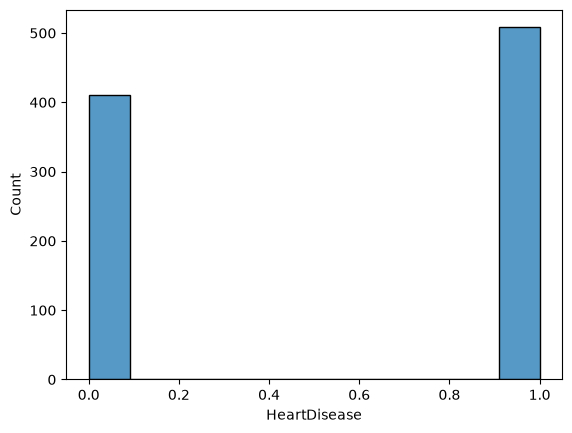

In [13]:
# Show the distribution
sns.histplot(df, x="HeartDisease")

In [14]:
# Another x y split to prevent a data leakage
X = df.drop(columns="HeartDisease", axis=1)
y = df['HeartDisease']

# Here, we tell the sampler what distribution we would like to have.
# Often times, this isn't necessary -- But sometimes it gets rid of far
# too much data if you don't.
strategy = {
    0: 410,
    1: 410
}

# use ClusterCentroids to undersample
# but also using a sampling strategy (to enforce a certain distribution)
sampler = ClusterCentroids(sampling_strategy=strategy, random_state=321)

# perform undersampling
X_resampled, y_resampled = sampler.fit_resample(X, y)

# reconstruct the dataframe
df_resampled = pd.DataFrame(X_resampled)
df_resampled["HeartDisease"] = y_resampled

<Axes: xlabel='HeartDisease', ylabel='Count'>

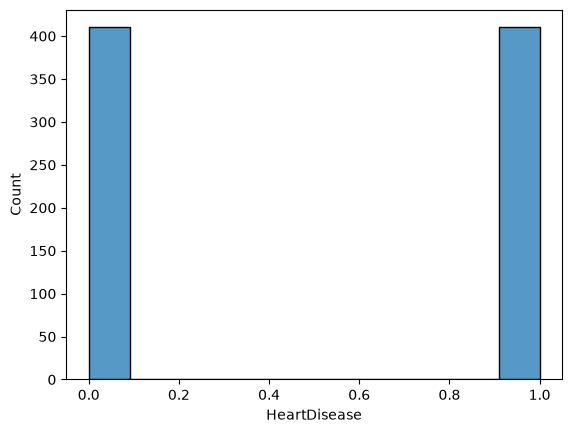

In [15]:
# let's study the target distribution now, much more even
sns.histplot(df_resampled, x="HeartDisease")

In [16]:
df.describe()

,Age,Sex,RestingBP,Cholesterol,FastingBS,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease,ChestPainType_ASY,ChestPainType_ATA,ChestPainType_NAP,ChestPainType_TA,RestingECG_LVH,RestingECG_Normal,RestingECG_ST
count,918.000000,918.000000,918.000000,918.000000,918.000000,918.000000,918.000000,918.000000,918.000000,918.000000,918.000000,918.000000,918.000000,918.000000,918.000000,918.000000,918.000000
mean,53.510893,0.789760,132.396514,198.799564,0.233115,136.809368,0.404139,0.887364,2.361656,0.553377,0.540305,0.188453,0.221133,0.050109,0.204793,0.601307,0.193900
std,9.432617,0.407701,18.514154,109.384145,0.423046,25.460334,0.490992,1.066570,0.607056,0.497414,0.498645,0.391287,0.415236,0.218289,0.403770,0.489896,0.395567
min,28.000000,0.000000,0.000000,0.000000,0.000000,60.000000,0.000000,-2.600000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,47.000000,1.000000,120.000000,173.250000,0.000000,120.000000,0.000000,0.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,54.000000,1.000000,130.000000,223.000000,0.000000,138.000000,0.000000,0.600000,2.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000
75%,60.000000,1.000000,140.000000,267.000000,0.000000,156.000000,1.000000,1.500000,3.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000
max,77.000000,1.000000,200.000000,603.000000,1.000000,202.000000,1.000000,6.200000,3.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


In [17]:
# some of the averages have changed, but it's expected since 
# we used downsampling and the dataset is fairly small as well
df_resampled.describe()

,Age,Sex,RestingBP,Cholesterol,FastingBS,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,ChestPainType_ASY,ChestPainType_ATA,ChestPainType_NAP,ChestPainType_TA,RestingECG_LVH,RestingECG_Normal,RestingECG_ST,HeartDisease
count,820.000000,820.000000,820.000000,820.000000,820.000000,820.000000,820.000000,820.000000,820.000000,820.000000,820.000000,820.000000,820.000000,820.000000,820.000000,820.000000,820.000000
mean,53.067073,0.764634,132.385366,210.114634,0.190244,138.329268,0.350000,0.848327,2.384146,0.490244,0.202439,0.221951,0.053659,0.202439,0.584146,0.163415,0.500000
std,9.576714,0.424486,18.974510,101.908223,0.392733,25.910362,0.477261,1.039802,0.615226,0.500210,0.402063,0.415812,0.225480,0.402063,0.493169,0.369969,0.500305
min,28.000000,0.000000,0.000000,0.000000,0.000000,60.000000,0.000000,-2.600000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,46.000000,1.000000,120.000000,185.750000,0.000000,120.000000,0.000000,0.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,54.000000,1.000000,130.000000,226.000000,0.000000,140.000000,0.000000,0.500000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.500000
75%,60.000000,1.000000,140.000000,270.000000,0.000000,158.000000,1.000000,1.500000,3.000000,1.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,1.000000
max,77.000000,1.000000,200.000000,603.000000,1.000000,202.000000,1.000000,6.200000,3.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


In [18]:
# switching to decimal notation for the variance checks
pd.set_option('display.float_format', lambda x: "%.2f" % x)

In [19]:
df.var(numeric_only=True)

Age                    88.97
Sex                     0.17
RestingBP             342.77
Cholesterol         11964.89
FastingBS               0.18
MaxHR                 648.23
ExerciseAngina          0.24
Oldpeak                 1.14
ST_Slope                0.37
HeartDisease            0.25
ChestPainType_ASY       0.25
ChestPainType_ATA       0.15
ChestPainType_NAP       0.17
ChestPainType_TA        0.05
RestingECG_LVH          0.16
RestingECG_Normal       0.24
RestingECG_ST           0.16
dtype: float64

In [20]:
df_resampled.var(numeric_only=True)

Age                    91.71
Sex                     0.18
RestingBP             360.03
Cholesterol         10385.29
FastingBS               0.15
MaxHR                 671.35
ExerciseAngina          0.23
Oldpeak                 1.08
ST_Slope                0.38
ChestPainType_ASY       0.25
ChestPainType_ATA       0.16
ChestPainType_NAP       0.17
ChestPainType_TA        0.05
RestingECG_LVH          0.16
RestingECG_Normal       0.24
RestingECG_ST           0.14
HeartDisease            0.25
dtype: float64